# Attribution Recovery Evaluation
### EHR XAI Simulation Study

Computes and visualises three attribution recovery metrics, comparing each
IML method's output against the analytical ground-truth Shapley weights:

- **MAE** — non-normalised mean absolute error, on the original Shapley-value scale.
  Deliberately NOT scale-invariant: tells us the absolute size of the error, in the
  same units as the true Shapley weights.
- **Bias** — mean signed error on true signal positions (raw scale). Positive =
  systematic over-attribution of real drivers; negative = systematic
  under-attribution.
- **AUROC** — area under the ROC curve, treating the binarised ground truth
  (signal vs. noise) as labels and the absolute attribution score as the
  ranking variable.

All metrics are stratified by phenotype group and aggregated with 95% bootstrap CIs.

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from typing import Optional

# ── Paths ──────────────────────────────────────────────────────────────────
SIM_DIR    = '/home/hoepler/eICU_Real_World_Example/sim_outputs_advanced/'
OUTPUT_DIR = '/home/hoepler/eICU_Real_World_Example/simulation_results_advanced/'

SCENARIOS = {
    'baseline':         'N3000_V20_trig0.15_esc0.10_bg0.010_corr0.00_ac0.00',
    'high_noise':       'N3000_V20_trig0.15_esc0.10_bg0.050_corr0.00_ac0.00',
    'high_correlation': 'N3000_V20_trig0.15_esc0.10_bg0.010_corr0.30_ac0.40',
    'short_history':    'N3000_V10_trig0.15_esc0.10_bg0.010_corr0.00_ac0.00',
}

MODEL_KEYS   = ['gru', 'lstm', 'attn_gru', 'attn_lstm', 'cnn']
MODEL_LABELS = ['GRU', 'LSTM', 'AttnGRU', 'AttnLSTM', 'CNN']

METHOD_COLORS = {
    'KernelSHAP':       '#E69F00',
    'TimeSHAP':         '#56B4E9',
    'WindowSHAP-Stat':  '#009E73',
    'WindowSHAP-Slid':  '#44AA99',
    'WindowSHAP-Dyn':   '#117733',
    'IG':               '#CC79A7',
    'EG':               '#D55E00',
    'Attention':        '#0072B2',
}

ALL_METRICS = ['mae', 'bias', 'auroc']

METRIC_LABELS = {
    'mae':   'MAE',
    'bias':  'Bias (signal)',
    'auroc': 'AUROC',
}
METRIC_BETTER = {
    'mae':   'lower',
    'bias':  'zero',
    'auroc': 'higher',
}
# Reference line drawn on plots
METRIC_REF = {
    'mae':   0.0,
    'bias':  0.0,
    'auroc': 0.5,
}

PHENOTYPE_ORDER = [
    'trigger_only', 'escalation_only', 'chronic_only',
    'trigger+escalation', 'trigger+chronic',
    'escalation+chronic', 'all_three',
]
PHENOTYPE_LABELS = {
    'trigger_only':       'Trigger only',
    'escalation_only':    'Escalation only',
    'chronic_only':       'Chronic only',
    'trigger+escalation': 'Trigger + Escalation',
    'trigger+chronic':    'Trigger + Chronic',
    'escalation+chronic': 'Escalation + Chronic',
    'all_three':          'All three',
}

print('Setup complete.')

Setup complete.


## 1. Metric Functions

In [2]:
# ══════════════════════════════════════════════════════════════════════════
# All metric functions operate on |attribution| (absolute attribution score)
# vs. the raw ground-truth Shapley weight, for a single patient, flattened
# over all (visit, code) triples.
# ══════════════════════════════════════════════════════════════════════════

def mae(attr: np.ndarray, gt: np.ndarray) -> float:
    """
    Non-normalised mean absolute error, on the ORIGINAL Shapley-value
    scale (e.g. units where the trigger feature's true weight is 5.0).

    Deliberately NOT scale-invariant: this tells us the absolute size of
    the attribution error, in the same units as the true Shapley weights.
    A method whose raw scores live on a different numeric scale than the
    true Shapley values will show a larger raw MAE even if its ranking is
    correct — which is itself diagnostic of a scale mismatch.
    """
    return float(np.mean(np.abs(attr - gt)))


def bias(attr: np.ndarray, gt: np.ndarray) -> float:
    """
    Mean SIGNED error (attribution minus ground truth), on the raw scale,
    computed only over ground-truth SIGNAL positions (gt > 0).

      bias > 0  ->  method systematically OVER-attributes true signal
      bias < 0  ->  method systematically UNDER-attributes true signal
      bias ≈ 0  ->  errors are not systematically directional (though this
                    does not imply small absolute error — see MAE)
    """
    signal_mask = gt > 0
    if signal_mask.sum() == 0:
        return np.nan
    return float(np.mean(attr[signal_mask] - gt[signal_mask]))


def auroc(attr: np.ndarray, gt: np.ndarray) -> float:
    """
    Area under the ROC curve. Binarised GT (signal vs noise) as labels,
    absolute attribution scores as the ranking/score variable.
    0.5 = random, 1.0 = perfect separation of signal from noise.
    """
    signal_mask = (gt > 0).astype(int)
    if signal_mask.sum() == 0 or (signal_mask == 0).sum() == 0:
        return np.nan
    return float(roc_auc_score(signal_mask, attr))


def bootstrap_ci(values, n_bootstrap=1000, ci=0.95, seed=42):
    """Returns (mean, lower_ci, upper_ci)."""
    rng  = np.random.default_rng(seed)
    vals = values[~np.isnan(values)]
    if len(vals) == 0:
        return np.nan, np.nan, np.nan
    mean = float(np.mean(vals))
    boot = np.array([
        np.mean(rng.choice(vals, size=len(vals), replace=True))
        for _ in range(n_bootstrap)
    ])
    alpha = (1 - ci) / 2
    return mean, float(np.percentile(boot, alpha * 100)), \
                 float(np.percentile(boot, (1 - alpha) * 100))


print('Metric functions defined: ' + ', '.join(ALL_METRICS))

Metric functions defined: mae, bias, auroc


## 2. Toy Example — Verify Metric Calculations

In [3]:
# 3 visits x 3 codes = 9 triples
# Signal positions: (1,1)=5.0, (2,1)=0.5, (3,2)=0.5
gt_toy   = np.array([5.0, 0.0, 0.0, 0.5, 0.0, 0.0, 0.0, 0.5, 0.0])
method_A = np.array([4.8, 0.2, 0.1, 0.6, 0.3, 0.1, 0.05, 0.4, 0.2])  # good, correct scale
method_B = np.array([0.1, 0.3, 0.1, 0.05, 0.4, 0.2, 0.6, 0.02, 0.3])  # poor ranking
method_C = method_A * 10                                              # good rank, WRONG SCALE

results = []
for name, attr in [
    ('Method A (good, correct scale)',  method_A),
    ('Method B (poor ranking)',         method_B),
    ('Method C (good rank, 10x scale)', method_C),
]:
    results.append({
        'Method':         name,
        'MAE':            round(mae(attr, gt_toy), 3),
        'Bias (signal)':  round(bias(attr, gt_toy), 3),
        'AUROC':          round(auroc(attr, gt_toy), 3),
    })

toy_df = pd.DataFrame(results)
print('Toy example results')
print('MAE: lower better | Bias: closer to 0 better | AUROC: higher better (0.5 = random)\n')
print('Note: Method A and Method C have identical AUROC (scale-invariant ranking),')
print('but Method C has a 10x larger MAE and a strongly positive bias — information')
print('that AUROC alone cannot reveal.\n')
display(toy_df)

Toy example results
MAE: lower better | Bias: closer to 0 better | AUROC: higher better (0.5 = random)

Note: Method A and Method C have identical AUROC (scale-invariant ranking),
but Method C has a 10x larger MAE and a strongly positive bias — information
that AUROC alone cannot reveal.



,Method,MAE,Bias (signal),AUROC
0,"Method A (good, correct scale)",0.150,-0.067,1.000
1,Method B (poor ranking),0.859,-1.943,0.028
2,"Method C (good rank, 10x scale)",6.833,17.333,1.000


## 3. Load Data

In [4]:
# ── Set scenario ────────────────────────────────────────────────────────────
SCENARIO_NAME = 'baseline'   # baseline | high_noise | high_correlation | short_history

TAG        = SCENARIOS[SCENARIO_NAME]
STORE_PATH = os.path.join(OUTPUT_DIR, f'scenario_store_{SCENARIO_NAME}.pkl')
out        = os.path.join(OUTPUT_DIR, SCENARIO_NAME)

with open(STORE_PATH, 'rb') as f:
    _store = pickle.load(f)

feature_names = _store['feature_names']
n_visits      = _store['n_visits']
n_static      = _store.get('n_static', 2)
n_tokens      = _store.get('n_tokens', len(feature_names) - n_static)
pid_test      = _store['pid_test']
y_test        = _store['y_test']
gt_ntf_full   = _store['gt_ntf']   # (N_patients, T, n_tokens)

labels = pd.read_csv(
    os.path.join(SIM_DIR, f'phenotype_labels_gt_{TAG}.csv'))

T = n_visits
P = n_tokens

print(f'Scenario : {SCENARIO_NAME}')
print(f'T={T}, P={P}, N_test={len(pid_test)}')
nz = (gt_ntf_full[(pid_test - 1).astype(int)] != 0).sum()
print(f'GT non-zero (signal) positions in test set: {nz:,}')

Scenario : baseline
T=20, P=140, N_test=600
GT non-zero (signal) positions in test set: 3,199


## 4. Evaluate All Methods

In [5]:
def evaluate_method(attr_ntf, gt_ntf, pid_test, pheno_labels,
                    method_name, model_name, scenario_name):
    """
    Compute MAE, Bias, and AUROC for every test patient. attr_ntf is
    (N, T, n_tokens); we use |attr| throughout so that signed
    gradient-based attributions (IG/EG) are on the same footing as
    inherently non-negative methods.
    """
    records = []
    for i, pid in enumerate(pid_test):
        gt_pat = gt_ntf[int(pid) - 1, :, :P].ravel()
        at_pat = np.abs(attr_ntf[i,   :, :P]).ravel()
        row    = pheno_labels.loc[pheno_labels['patient_id'] == pid]
        group  = row['group_gt'].values[0] if len(row) > 0 else 'unknown'
        records.append(dict(
            patient_id = int(pid),
            group_gt   = group,
            method     = method_name,
            model      = model_name,
            scenario   = scenario_name,
            mae        = mae(at_pat, gt_pat),
            bias       = bias(at_pat, gt_pat),
            auroc      = auroc(at_pat, gt_pat),
        ))
    return pd.DataFrame(records)


all_evals = []

# ── Integrated Gradients ──────────────────────────────────────────────────
ig_path = os.path.join(out, 'ig_arrays.npz')
if os.path.exists(ig_path):
    ig = np.load(ig_path)
    for mkey, mlabel in zip(MODEL_KEYS, MODEL_LABELS):
        arr_key = f'ig_{mkey}_ntf'
        if arr_key in ig:
            all_evals.append(evaluate_method(
                ig[arr_key], gt_ntf_full, pid_test, labels,
                'IG', mlabel, SCENARIO_NAME))
    print('IG loaded.')

# ── Expected Gradients ────────────────────────────────────────────────────
eg_path = os.path.join(out, 'eg_arrays.npz')
if os.path.exists(eg_path):
    eg = np.load(eg_path)
    for mkey, mlabel in zip(MODEL_KEYS, MODEL_LABELS):
        arr_key = f'eg_{mkey}_ntf'
        if arr_key in eg:
            all_evals.append(evaluate_method(
                eg[arr_key], gt_ntf_full, pid_test, labels,
                'EG', mlabel, SCENARIO_NAME))
    print('EG loaded.')

# ── KernelSHAP ───────────────────────────────────────────────────────────
ks_path = os.path.join(out, 'kernelshap_results.npz')
if os.path.exists(ks_path):
    ks           = np.load(ks_path, allow_pickle=True)
    case_indices = ks['case_indices'].tolist()
    case_pids_ks = pid_test[case_indices]
    for mkey, mlabel in zip(MODEL_KEYS, MODEL_LABELS):
        arr_key = f'shap_ntf_{mkey}'
        if arr_key in ks:
            all_evals.append(evaluate_method(
                ks[arr_key], gt_ntf_full, case_pids_ks, labels,
                'KernelSHAP', mlabel, SCENARIO_NAME))
    print('KernelSHAP loaded.')

# ── TimeSHAP ──────────────────────────────────────────────────────────────
for mkey, mlabel in zip(MODEL_KEYS, MODEL_LABELS):
    ts_path = os.path.join(out, f'timeshap_cell_ntf_{mkey}.npz')
    if os.path.exists(ts_path):
        ts     = np.load(ts_path)
        ts_ntf = ts[f'ts_{mkey}_ntf']
        case_idx_ts  = [i for i, pid in enumerate(pid_test)
                        if ts_ntf[i].sum() != 0]
        if case_idx_ts:
            all_evals.append(evaluate_method(
                ts_ntf[case_idx_ts], gt_ntf_full,
                pid_test[case_idx_ts], labels,
                'TimeSHAP', mlabel, SCENARIO_NAME))
print('TimeSHAP loaded.')

# ── WindowSHAP ───────────────────────────────────────────────────────────
for mkey, mlabel in zip(MODEL_KEYS, MODEL_LABELS):
    ws_path = os.path.join(out, f'windowshap_{mkey}.npz')
    if os.path.exists(ws_path):
        ws           = np.load(ws_path)
        tp_ws        = ws['tp_ws']
        case_pids_ws = pid_test[tp_ws]
        for variant, arr_key in [
            ('WindowSHAP-Stat', 'stat_ntf'),
            ('WindowSHAP-Slid', 'slid_ntf'),
            ('WindowSHAP-Dyn',  'dyn_ntf'),
        ]:
            if arr_key in ws:
                all_evals.append(evaluate_method(
                    ws[arr_key], gt_ntf_full, case_pids_ws, labels,
                    variant, mlabel, SCENARIO_NAME))
print('WindowSHAP loaded.')

eval_df = pd.concat(all_evals, ignore_index=True)
print(f'\nTotal evaluations: {len(eval_df):,}')
display(eval_df.groupby(['method', 'model'])['mae'].count().unstack())

IG loaded.
EG loaded.
KernelSHAP loaded.
TimeSHAP loaded.
WindowSHAP loaded.

Total evaluations: 6,200


model,AttnGRU,AttnLSTM,CNN,GRU,LSTM
method,,,,,
EG,600,600,600,600,600
IG,600,600,600,600,600
KernelSHAP,8,8,8,8,8
TimeSHAP,8,8,8,8,8
WindowSHAP-Dyn,8,8,8,8,8
WindowSHAP-Slid,8,8,8,8,8
WindowSHAP-Stat,8,8,8,8,8


## 5. Aggregate with Bootstrap CIs

In [8]:
def aggregate_metrics(eval_df,
                      group_by=None,
                      metrics=None,
                      n_bootstrap=1000):
    if group_by is None:
        group_by = ['method', 'model', 'scenario', 'group_gt']
    if metrics is None:
        metrics = ALL_METRICS
    rows = []
    for keys, sub in eval_df.groupby(group_by):
        key_dict = dict(zip(
            group_by,
            keys if isinstance(keys, tuple) else [keys]))
        for metric in metrics:
            vals = sub[metric].dropna().values
            mean, lo, hi = bootstrap_ci(vals, n_bootstrap=n_bootstrap)
            rows.append({**key_dict,
                         'metric':   metric,
                         'n':        len(vals),
                         'mean':     round(mean, 4) if not np.isnan(mean) else np.nan,
                         'ci_lower': round(lo,   4) if not np.isnan(lo)   else np.nan,
                         'ci_upper': round(hi,   4) if not np.isnan(hi)   else np.nan})
    return pd.DataFrame(rows)


agg_df = aggregate_metrics(eval_df)
print(f'Aggregated rows: {len(agg_df)}')
display(agg_df.head(12))

Aggregated rows: 840


,method,model,scenario,group_gt,metric,n,mean,ci_lower,ci_upper
0,EG,AttnGRU,baseline,all_three,mae,1,0.0066,0.0066,0.0066
1,EG,AttnGRU,baseline,all_three,bias,1,-0.2174,-0.2174,-0.2174
2,EG,AttnGRU,baseline,all_three,auroc,1,0.9901,0.9901,0.9901
3,EG,AttnGRU,baseline,chronic_only,mae,35,0.0055,0.0050,0.0060
4,EG,AttnGRU,baseline,chronic_only,bias,35,0.1682,0.0964,0.2437
5,EG,AttnGRU,baseline,chronic_only,auroc,35,0.9984,0.9979,0.9987
6,EG,AttnGRU,baseline,escalation+chronic,mae,21,0.0058,0.0053,0.0063
7,EG,AttnGRU,baseline,escalation+chronic,bias,21,-0.0582,-0.1126,-0.0099
8,EG,AttnGRU,baseline,escalation+chronic,auroc,21,0.9786,0.9720,0.9840
9,EG,AttnGRU,baseline,escalation_only,mae,101,0.0034,0.0032,0.0036


## 6. Plot: Dot-and-Whisker — Metric by Phenotype Group

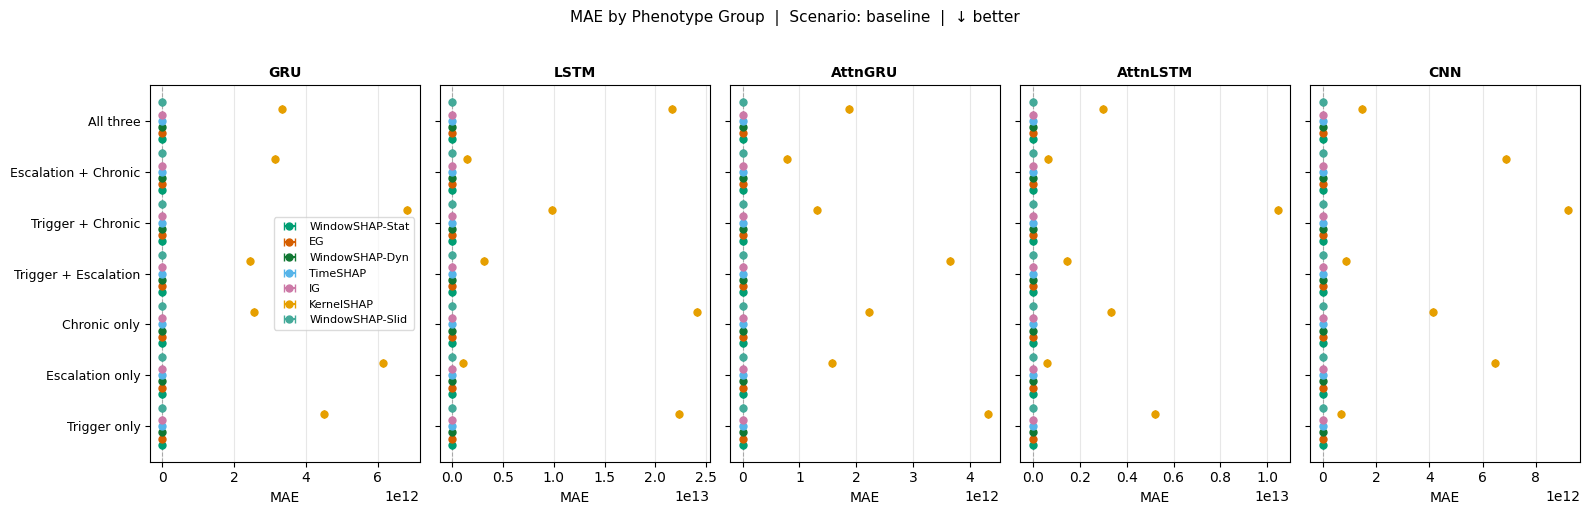

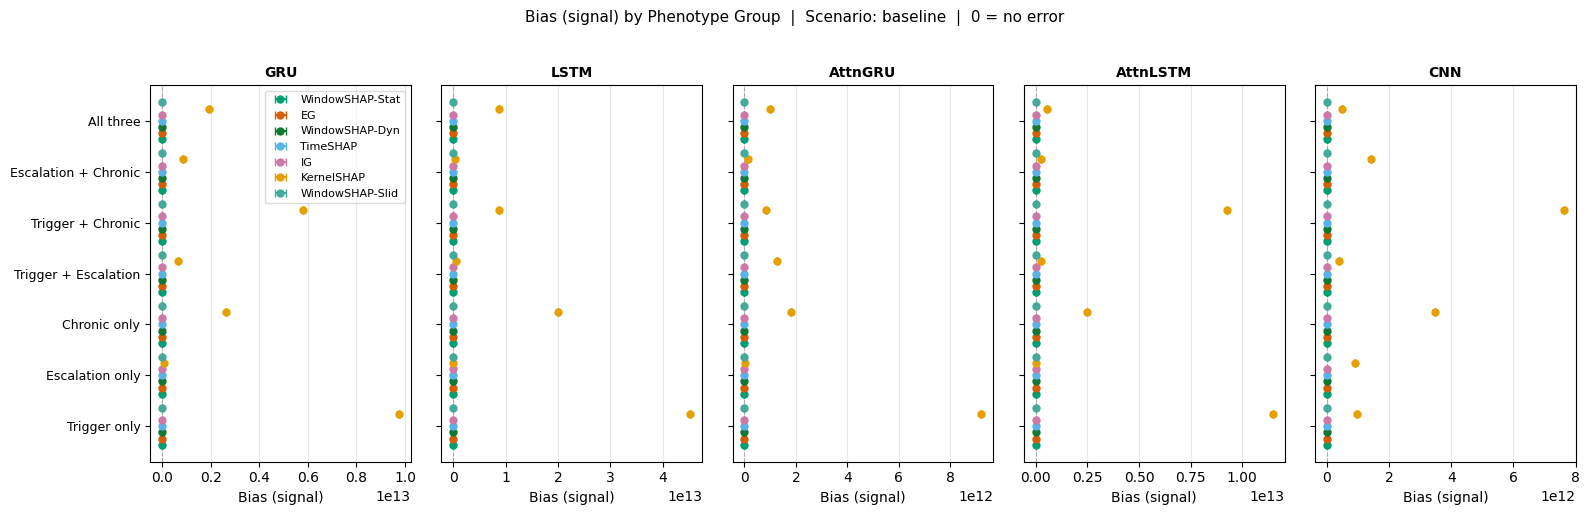

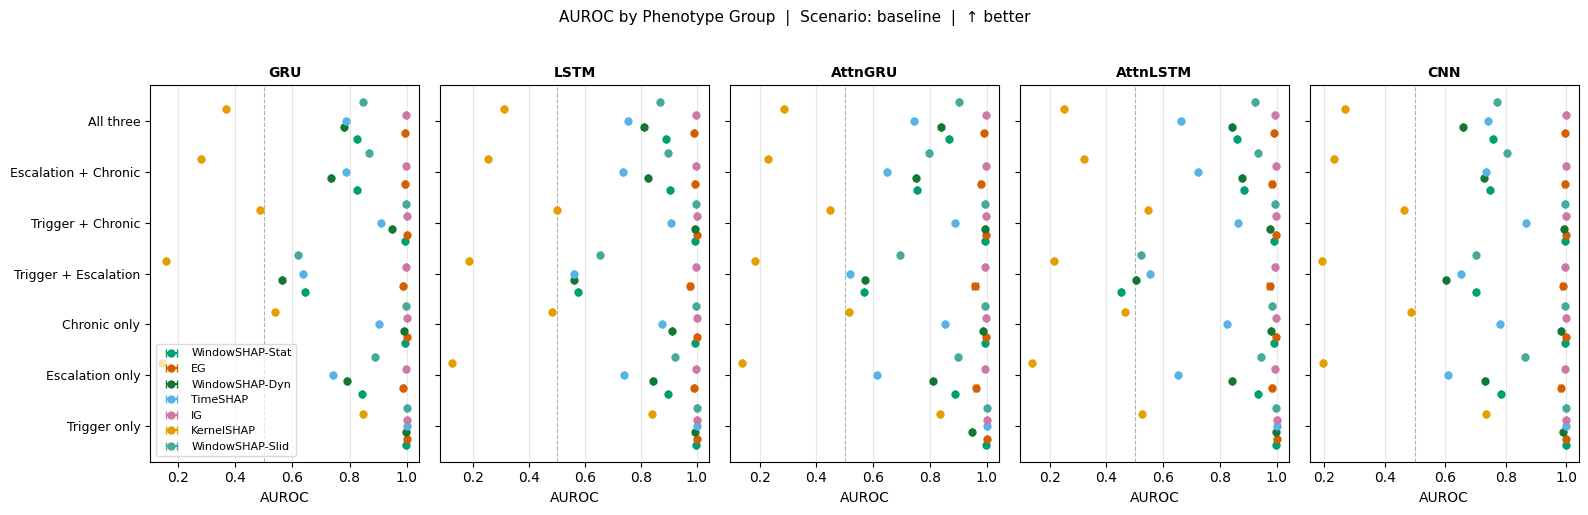

In [9]:
def plot_metric_by_phenotype(agg_df, metric='auroc',
                              scenario='baseline', methods=None,
                              models=None, figsize=(16, 5),
                              save_path=None):
    sub = agg_df[
        (agg_df['metric']   == metric) &
        (agg_df['scenario'] == scenario) &
        (agg_df['group_gt'].isin(PHENOTYPE_ORDER))
    ].copy()
    if methods is not None:
        sub = sub[sub['method'].isin(methods)]
    if models is not None:
        sub = sub[sub['model'].isin(models)]

    sub['group_gt'] = pd.Categorical(
        sub['group_gt'], categories=PHENOTYPE_ORDER, ordered=True)
    sub = sub.sort_values('group_gt')

    model_list  = [m for m in MODEL_LABELS if m in sub['model'].unique()]
    method_list = list(sub['method'].unique())
    groups      = [g for g in PHENOTYPE_ORDER if g in sub['group_gt'].values]
    y_pos       = np.arange(len(groups))

    fig, axes = plt.subplots(1, len(model_list),
                              figsize=figsize, sharey=True)
    if len(model_list) == 1:
        axes = [axes]

    for ax, model in zip(axes, model_list):
        model_df = sub[sub['model'] == model]
        for k, method in enumerate(method_list):
            color  = METHOD_COLORS.get(method, f'C{k}')
            offset = (k - len(method_list) / 2 + 0.5) * 0.12
            m_df   = model_df[model_df['method'] == method]
            for j, group in enumerate(groups):
                row = m_df[m_df['group_gt'] == group]
                if len(row) == 0:
                    continue
                r = row.iloc[0]
                ax.errorbar(
                    x=r['mean'], y=y_pos[j] + offset,
                    xerr=[[r['mean'] - r['ci_lower']],
                          [r['ci_upper'] - r['mean']]],
                    fmt='o', color=color, capsize=3, markersize=5,
                    label=method if j == 0 else '_nolegend_')

        ax.set_yticks(y_pos)
        ax.set_yticklabels(
            [PHENOTYPE_LABELS.get(g, g) for g in groups], fontsize=9)
        ax.set_xlabel(METRIC_LABELS[metric], fontsize=10)
        ax.set_title(model, fontsize=10, fontweight='bold')
        ref = METRIC_REF.get(metric)
        if ref is not None:
            ax.axvline(ref, color='grey', linestyle='--',
                       linewidth=0.8, alpha=0.6)
        ax.grid(axis='x', alpha=0.3)

    axes[0].legend(loc='best', fontsize=8, framealpha=0.7)
    direction = {'higher': '\u2191 better', 'lower': '\u2193 better',
                'zero': '0 = no error'}[METRIC_BETTER[metric]]
    fig.suptitle(
        f'{METRIC_LABELS[metric]} by Phenotype Group  |  '
        f'Scenario: {scenario}  |  {direction}',
        fontsize=11, y=1.02)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


for metric in ALL_METRICS:
    plot_metric_by_phenotype(agg_df, metric=metric, scenario=SCENARIO_NAME)

## 7. Plot: Bar Chart Summary — All Metrics, One Model

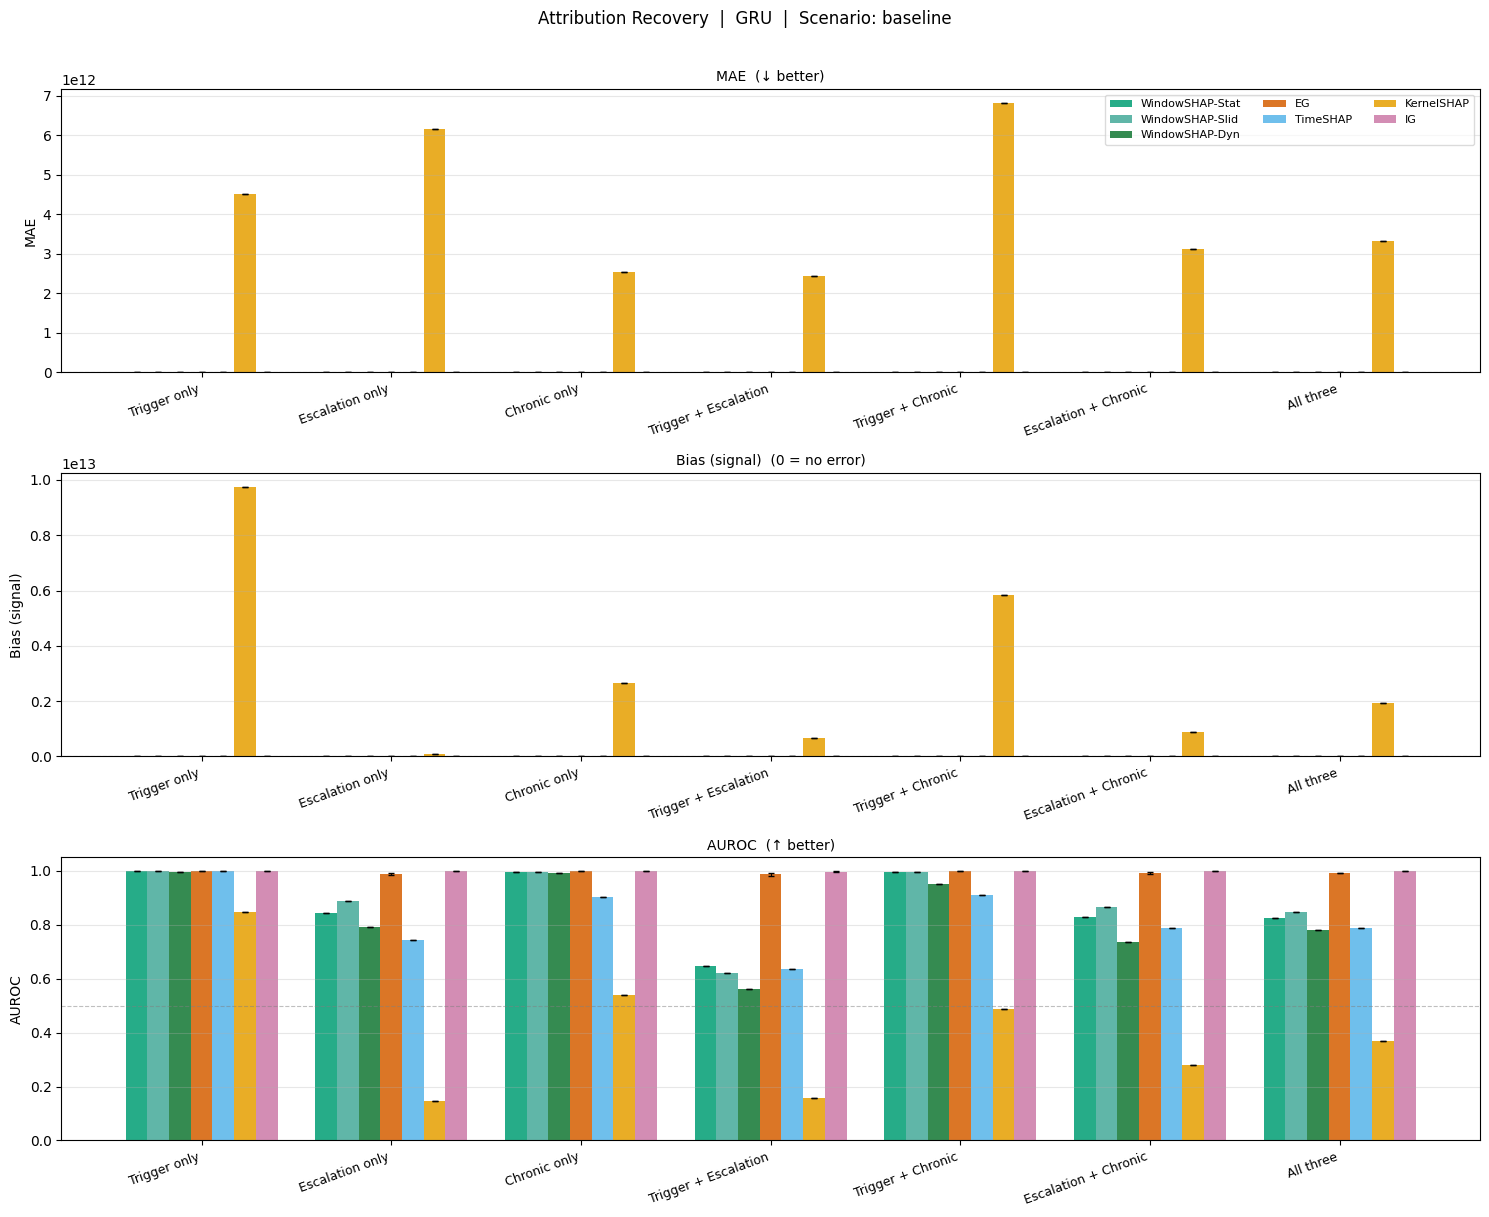

In [10]:
def plot_metrics_summary(agg_df, scenario='baseline', model='GRU',
                         figsize=(15, 12), save_path=None):
    metrics = ALL_METRICS
    fig, axes = plt.subplots(len(metrics), 1, figsize=figsize)
    if len(metrics) == 1:
        axes = [axes]

    for ax, metric in zip(axes, metrics):
        sub = agg_df[
            (agg_df['metric']   == metric) &
            (agg_df['scenario'] == scenario) &
            (agg_df['model']    == model) &
            (agg_df['group_gt'].isin(PHENOTYPE_ORDER))
        ].copy()
        sub['group_gt'] = pd.Categorical(
            sub['group_gt'], categories=PHENOTYPE_ORDER, ordered=True)
        sub = sub.sort_values('group_gt')

        methods   = list(sub['method'].unique())
        groups    = [g for g in PHENOTYPE_ORDER
                     if g in sub['group_gt'].values]
        x         = np.arange(len(groups))
        bar_width = 0.8 / max(len(methods), 1)

        for k, method in enumerate(methods):
            color  = METHOD_COLORS.get(method, f'C{k}')
            offset = (k - len(methods) / 2 + 0.5) * bar_width
            m_df   = sub[sub['method'] == method]
            means, errs = [], []
            for group in groups:
                row = m_df[m_df['group_gt'] == group]
                if len(row) == 0:
                    means.append(np.nan)
                    errs.append(np.nan)
                else:
                    r = row.iloc[0]
                    means.append(r['mean'])
                    errs.append(max(r['mean'] - r['ci_lower'],
                                   r['ci_upper'] - r['mean']))
            ax.bar(x + offset, means, bar_width, label=method,
                   color=color, alpha=0.85,
                   yerr=errs, capsize=2,
                   error_kw=dict(elinewidth=0.8))

        ax.set_xticks(x)
        ax.set_xticklabels(
            [PHENOTYPE_LABELS.get(g, g) for g in groups],
            fontsize=9, rotation=20, ha='right')
        ax.set_ylabel(METRIC_LABELS[metric], fontsize=10)
        direction = {'higher': '\u2191 better', 'lower': '\u2193 better',
                    'zero': '0 = no error'}[METRIC_BETTER[metric]]
        ax.set_title(f'{METRIC_LABELS[metric]}  ({direction})', fontsize=10)
        ref = METRIC_REF.get(metric)
        if ref is not None:
            ax.axhline(ref, color='grey', linestyle='--',
                       linewidth=0.8, alpha=0.5)
        ax.grid(axis='y', alpha=0.3)
        if metric == metrics[0]:
            ax.legend(loc='best', fontsize=8, ncol=3, framealpha=0.7)

    fig.suptitle(
        f'Attribution Recovery  |  {model}  |  Scenario: {scenario}',
        fontsize=12, y=1.01)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_metrics_summary(agg_df, scenario=SCENARIO_NAME, model='GRU')

## 8. Plot: Scenario Heatmap (sensitivity analysis)

Run sections 3–5 for each scenario first, then concatenate `eval_df` across scenarios before calling `aggregate_metrics`.

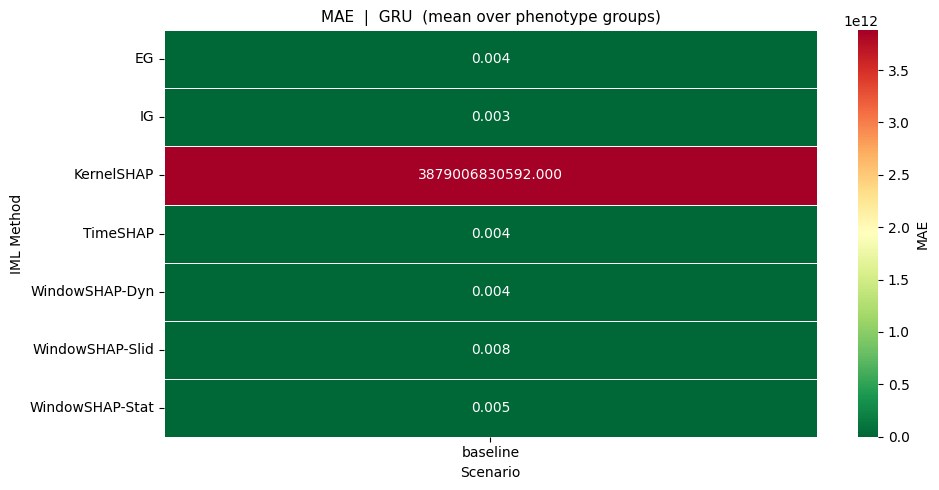

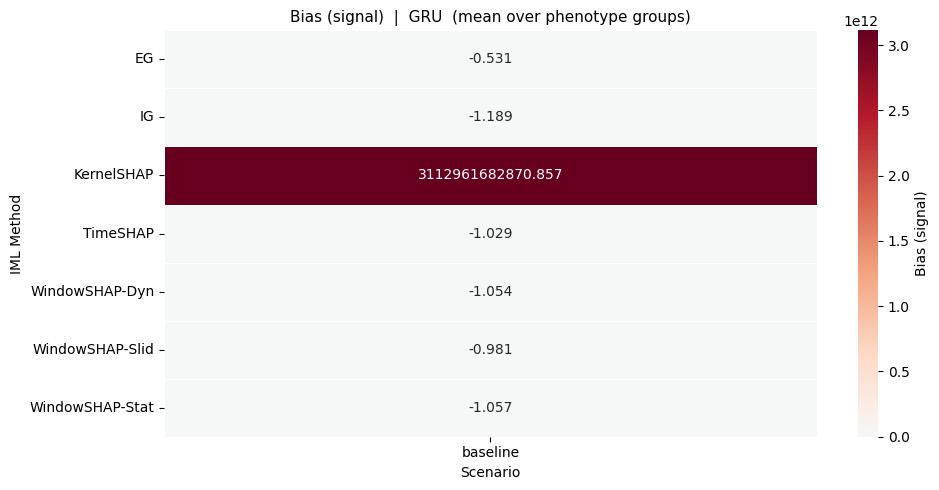

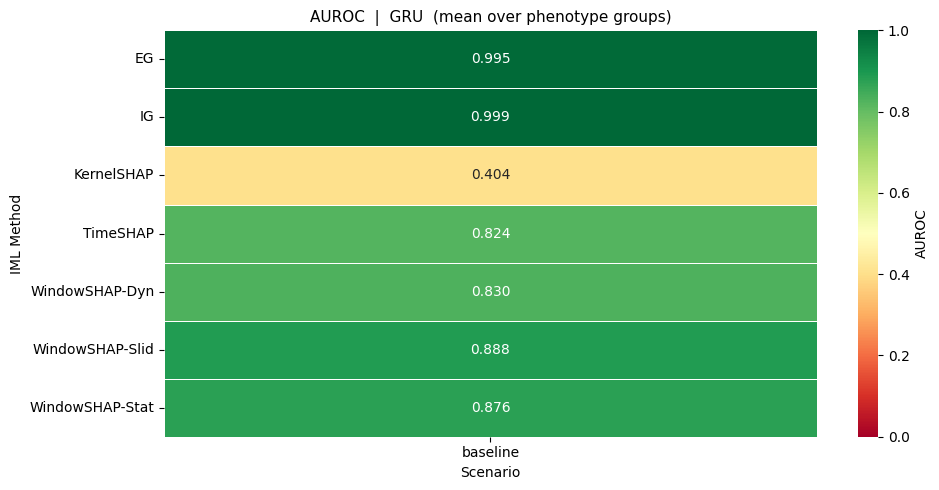

In [11]:
def plot_scenario_heatmap(agg_df, metric='auroc', model='GRU',
                           figsize=(10, 5), save_path=None):
    sub = agg_df[
        (agg_df['metric'] == metric) &
        (agg_df['model']  == model)
    ]
    pivot = (sub
             .groupby(['method', 'scenario'])['mean']
             .mean()
             .unstack('scenario'))

    fig, ax = plt.subplots(figsize=figsize)
    if METRIC_BETTER[metric] == 'higher':
        cmap, vmin, vmax, center = 'RdYlGn', 0, 1, None
    elif METRIC_BETTER[metric] == 'lower':
        cmap, vmin, vmax, center = 'RdYlGn_r', None, None, None
    else:  # 'zero' -> diverging, centred at 0
        cmap, vmin, vmax, center = 'RdBu_r', None, None, 0

    sns.heatmap(
        pivot, ax=ax, cmap=cmap, annot=True, fmt='.3f',
        vmin=vmin, vmax=vmax, center=center, linewidths=0.5,
        cbar_kws={'label': METRIC_LABELS[metric]})
    ax.set_title(
        f'{METRIC_LABELS[metric]}  |  {model}  '
        f'(mean over phenotype groups)', fontsize=11)
    ax.set_xlabel('Scenario', fontsize=10)
    ax.set_ylabel('IML Method', fontsize=10)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


# With a single scenario this shows one column — useful once all scenarios are loaded
# Replace agg_df with combined_agg_df after loading all four scenarios
for metric in ALL_METRICS:
    plot_scenario_heatmap(agg_df, metric=metric, model='GRU')

## 9. Plot: Strip Plot — Full Per-Patient Distribution

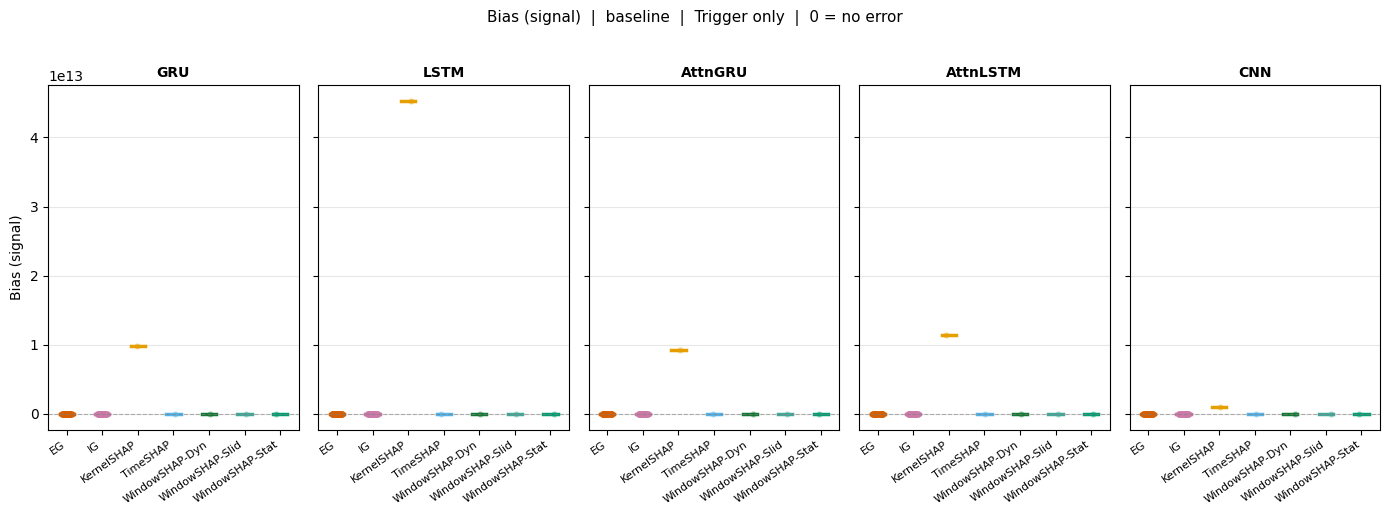

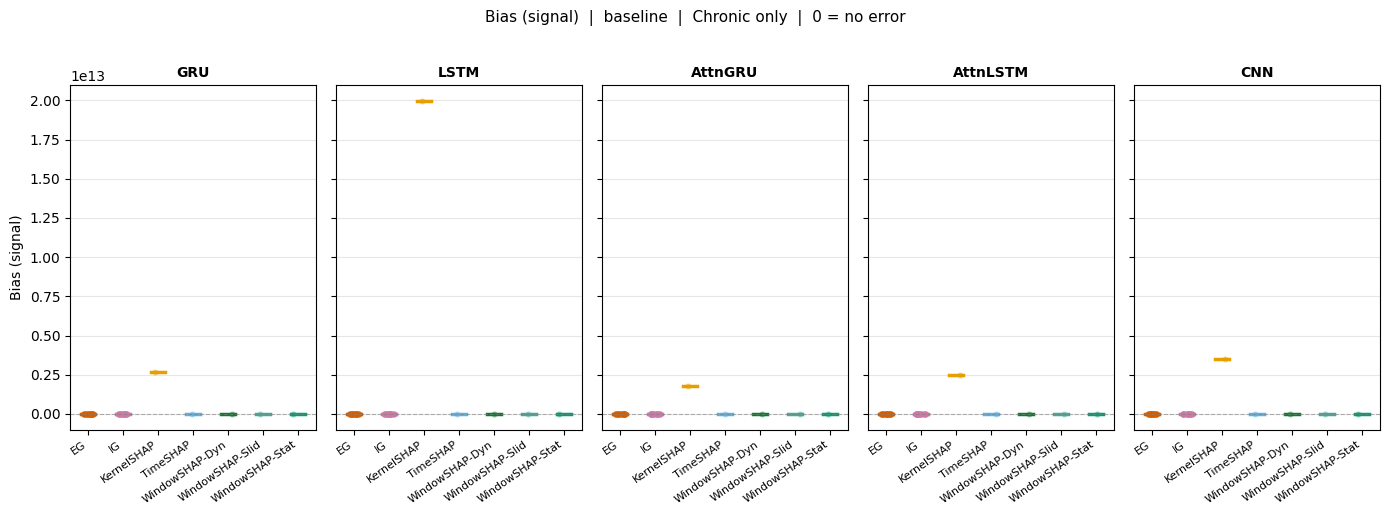

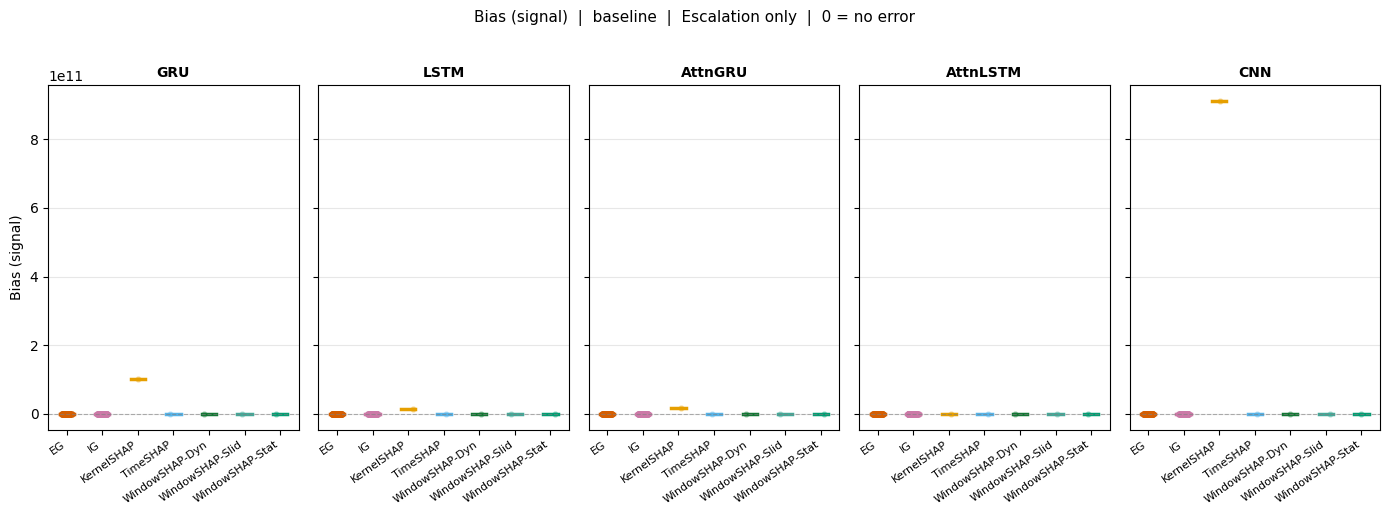

In [12]:
def plot_strip(eval_df, metric='auroc', scenario='baseline',
               group='trigger_only', figsize=(14, 5), save_path=None):
    sub = eval_df[
        (eval_df['scenario'] == scenario) &
        (eval_df['group_gt'] == group)
    ].dropna(subset=[metric])

    model_list = [m for m in MODEL_LABELS if m in sub['model'].unique()]
    fig, axes  = plt.subplots(1, len(model_list),
                               figsize=figsize, sharey=True)
    if len(model_list) == 1:
        axes = [axes]

    rng = np.random.default_rng(42)
    for ax, model in zip(axes, model_list):
        m_df    = sub[sub['model'] == model]
        methods = sorted(m_df['method'].unique())
        x_map   = {m: i for i, m in enumerate(methods)}

        for method in methods:
            color  = METHOD_COLORS.get(method, 'grey')
            vals   = m_df[m_df['method'] == method][metric].values
            x_base = x_map[method]
            jitter = rng.uniform(-0.15, 0.15, size=len(vals))
            ax.scatter(x_base + jitter, vals,
                       alpha=0.35, s=12, color=color)
            mean, lo, hi = bootstrap_ci(vals)
            ax.plot([x_base - 0.2, x_base + 0.2], [mean, mean],
                    color=color, linewidth=2.5)
            ax.plot([x_base, x_base], [lo, hi],
                    color=color, linewidth=1.5)

        ax.set_xticks(list(x_map.values()))
        ax.set_xticklabels(methods, rotation=35, ha='right', fontsize=8)
        ax.set_title(model, fontsize=10, fontweight='bold')
        ref = METRIC_REF.get(metric)
        if ref is not None:
            ax.axhline(ref, color='grey', linestyle='--',
                       linewidth=0.8, alpha=0.6)
        ax.grid(axis='y', alpha=0.3)

    axes[0].set_ylabel(METRIC_LABELS[metric], fontsize=10)
    direction = {'higher': '\u2191 better', 'lower': '\u2193 better',
                'zero': '0 = no error'}[METRIC_BETTER[metric]]
    fig.suptitle(
        f'{METRIC_LABELS[metric]}  |  {scenario}  |  '
        f'{PHENOTYPE_LABELS.get(group, group)}  |  {direction}',
        fontsize=11, y=1.02)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


for group in ['trigger_only', 'chronic_only', 'escalation_only']:
    plot_strip(eval_df, metric='bias', scenario=SCENARIO_NAME, group=group)

## 10. Export Results Table

In [13]:
wide = agg_df.copy()
wide['value_str'] = (
    wide['mean'].map(lambda x: f'{x:.3f}' if not pd.isna(x) else 'NA') +
    ' [' +
    wide['ci_lower'].map(lambda x: f'{x:.3f}' if not pd.isna(x) else 'NA') +
    ', ' +
    wide['ci_upper'].map(lambda x: f'{x:.3f}' if not pd.isna(x) else 'NA') +
    ']'
)

pivot_table = wide.pivot_table(
    index=['method', 'model', 'scenario', 'group_gt'],
    columns='metric',
    values='value_str',
    aggfunc='first',
).reset_index()
pivot_table.columns.name = None
pivot_table = pivot_table.rename(columns={
    'mae':   'MAE [95% CI]',
    'bias':  'Bias [95% CI]',
    'auroc': 'AUROC [95% CI]',
})

save_csv = os.path.join(out, 'attribution_metrics_summary.csv')
pivot_table.to_csv(save_csv, index=False)
print(f'Saved: {save_csv}')
display(pivot_table.head(20))

Saved: /home/hoepler/eICU_Real_World_Example/simulation_results_advanced/baseline/attribution_metrics_summary.csv


,method,model,scenario,group_gt,AUROC [95% CI],Bias [95% CI],MAE [95% CI]
0,EG,AttnGRU,baseline,all_three,"0.990 [0.990, 0.990]","-0.217 [-0.217, -0.217]","0.007 [0.007, 0.007]"
1,EG,AttnGRU,baseline,chronic_only,"0.998 [0.998, 0.999]","0.168 [0.096, 0.244]","0.005 [0.005, 0.006]"
2,EG,AttnGRU,baseline,escalation+chronic,"0.979 [0.972, 0.984]","-0.058 [-0.113, -0.010]","0.006 [0.005, 0.006]"
3,EG,AttnGRU,baseline,escalation_only,"0.964 [0.957, 0.971]","-0.222 [-0.268, -0.176]","0.003 [0.003, 0.004]"
4,EG,AttnGRU,baseline,none,"NA [NA, NA]","NA [NA, NA]","0.003 [0.002, 0.003]"
5,EG,AttnGRU,baseline,trigger+chronic,"0.999 [0.998, 0.999]","-0.440 [-0.500, -0.382]","0.006 [0.005, 0.006]"
6,EG,AttnGRU,baseline,trigger+escalation,"0.959 [0.950, 0.968]","-0.382 [-0.502, -0.269]","0.005 [0.005, 0.005]"
7,EG,AttnGRU,baseline,trigger_only,"1.000 [1.000, 1.000]","-0.738 [-1.085, -0.432]","0.004 [0.004, 0.004]"
8,EG,AttnLSTM,baseline,all_three,"0.991 [0.991, 0.991]","-0.230 [-0.230, -0.230]","0.007 [0.007, 0.007]"
9,EG,AttnLSTM,baseline,chronic_only,"0.998 [0.997, 0.998]","0.151 [0.087, 0.212]","0.007 [0.007, 0.008]"
